**SETUP ENVIRONMENT, GPU CHECK, & INSTALL DEPENDENCIES**

In [ ]:
!nvidia-smi

# Install library pendukung
!pip install -q timm scikit-learn seaborn matplotlib tqdm kagglehub

import os
import shutil
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support,
    f1_score
)

# Set seed agar hasil eksperimen dapat direproduksi (Reproducibility)
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device yang digunakan: {device}")


Tue Oct  6 00:49:17 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   56C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

**DOWNLOAD & EKSTRAK DATASET LANGSUNG DI COLAB**

In [ ]:
# Metode 1: Menggunakan kagglehub (Otomatis & Tanpa ribet mengatur token file)
import kagglehub

print("Mengunduh dataset dari Kaggle...")
dataset_raw_path = kagglehub.dataset_download("mexwell/tea-sickness-dataset")
print(f"Dataset berhasil diunduh ke: {dataset_raw_path}")

# Mencari direktori root gambar yang berisi folder-folder kelas
def find_image_folder(base_dir):
    for root, dirs, files in os.walk(base_dir):
        # Jika folder memiliki subfolder (kelas daun teh), ini adalah root dataset
        if len(dirs) >= 6:
            return root
    return base_dir

DATA_DIR = find_image_folder(dataset_raw_path)
print(f"Direktori data yang digunakan: {DATA_DIR}")
print("Daftar kelas yang ditemukan:", os.listdir(DATA_DIR))


Mengunduh dataset dari Kaggle...


100%|██████████| 740M/740M [00:08<00:00, 87.1MB/s]

Extracting files...


Dataset berhasil diunduh ke: /root/.cache/kagglehub/datasets/mexwell/tea-sickness-dataset/versions/1
Direktori data yang digunakan: /root/.cache/kagglehub/datasets/mexwell/tea-sickness-dataset/versions/1/j32xdt2ff5-2/tea sickness dataset/tea sickness dataset
Daftar kelas yang ditemukan: ['bird eye spot', 'Anthracnose', 'white spot', 'healthy', 'brown blight', 'red leaf spot', 'algal leaf', 'gray light']


**EXPLORATORY DATA ANALYSIS (EDA) & VISUALISASI KELAS**


=== DISTRIBUSI JUMLAH DATA PER KELAS ===
   Nama Kelas  Jumlah Citra
  Anthracnose           100
   algal leaf           113
bird eye spot           100
 brown blight           113
   gray light           100
      healthy            74
red leaf spot           143
   white spot           142


/tmp/ipykernel_697/1654784410.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_classes, x='Jumlah Citra', y='Nama Kelas', palette='viridis')


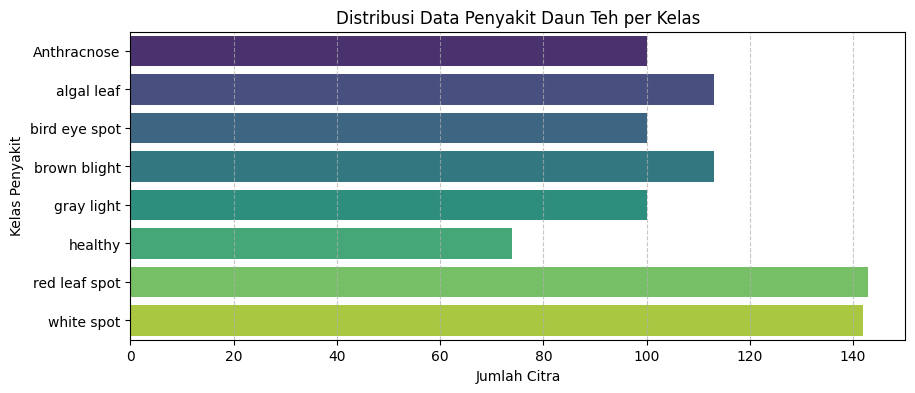

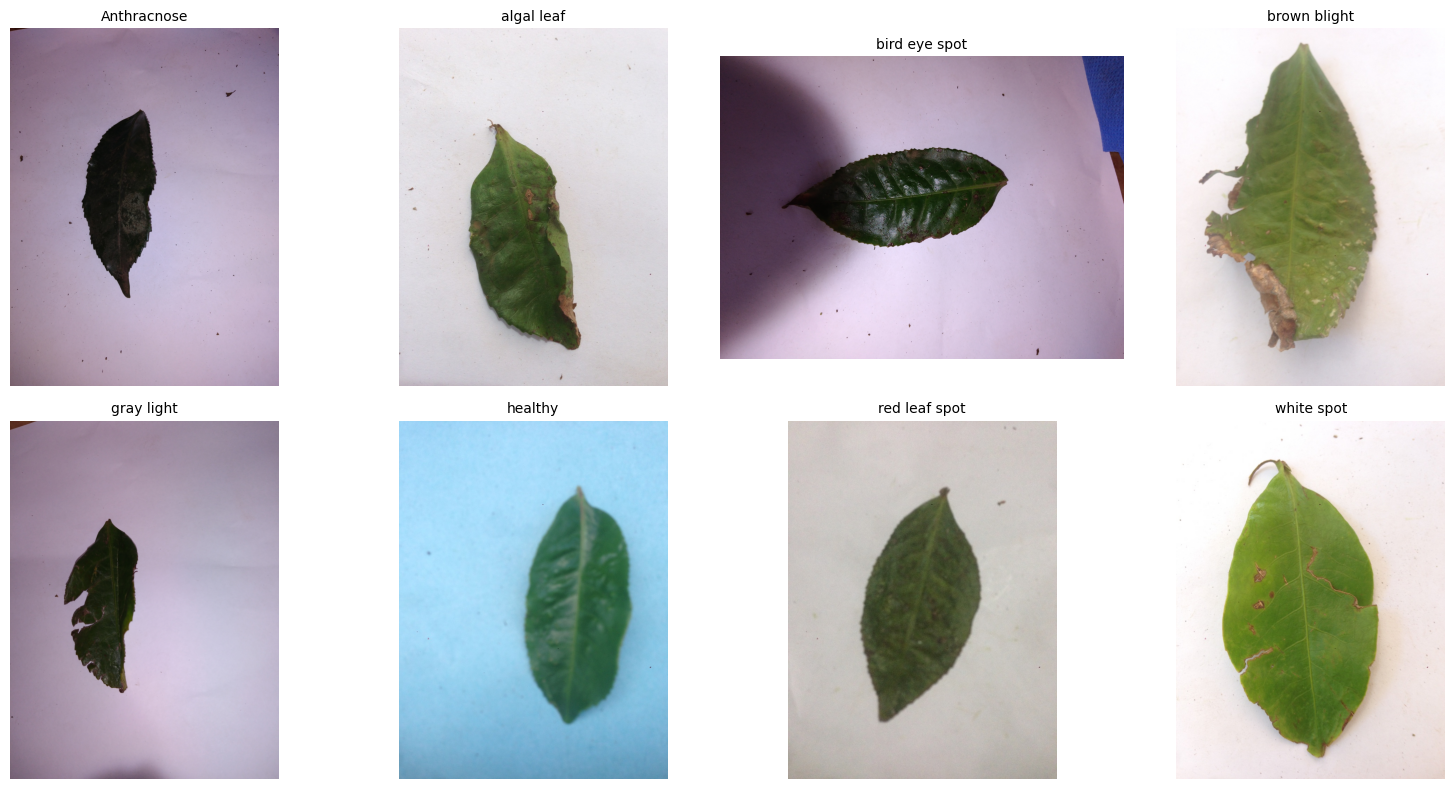

In [ ]:
classes = [d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d))]
classes.sort()

class_counts = {}
for cls in classes:
    cls_folder = os.path.join(DATA_DIR, cls)
    n_images = len([f for f in os.listdir(cls_folder) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
    class_counts[cls] = n_images

df_classes = pd.DataFrame(list(class_counts.items()), columns=['Nama Kelas', 'Jumlah Citra'])
print("\n=== DISTRIBUSI JUMLAH DATA PER KELAS ===")
print(df_classes.to_string(index=False))

# Plot distribusi kelas
plt.figure(figsize=(10, 4))
sns.barplot(data=df_classes, x='Jumlah Citra', y='Nama Kelas', palette='viridis')
plt.title("Distribusi Data Penyakit Daun Teh per Kelas")
plt.xlabel("Jumlah Citra")
plt.ylabel("Kelas Penyakit")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

# Visualisasi sampel citra per kelas
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for idx, cls in enumerate(classes[:8]):
    cls_folder = os.path.join(DATA_DIR, cls)
    sample_img_name = os.listdir(cls_folder)[0]
    sample_img_path = os.path.join(cls_folder, sample_img_name)
    img = Image.open(sample_img_path)
    axes[idx].imshow(img)
    axes[idx].set_title(cls, fontsize=10)
    axes[idx].axis('off')

plt.tight_layout()
plt.show()


**DATA PREPROCESSING & DATA AUGMENTATION**


In [ ]:
# Standar resolusi untuk ViT dan ResNet50 adalah 224x224
IMG_SIZE = 224
BATCH_SIZE = 32

# Transformasi Training: Data Augmentation untuk mencegah Overfitting
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Transformasi Validation & Testing: Hanya resize & normalisasi (tanpa augmentasi acak)
test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Memuat dataset utuh
full_dataset = datasets.ImageFolder(root=DATA_DIR)
num_classes = len(full_dataset.classes)
print(f"Total gambar: {len(full_dataset)} | Total kelas: {num_classes}")

# Split Dataset: 70% Train, 15% Validation, 15% Test
total_size = len(full_dataset)
train_size = int(0.70 * total_size)
val_size = int(0.15 * total_size)
test_size = total_size - train_size - val_size

train_subset, val_subset, test_subset = random_split(
    full_dataset,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

# Wrapper agar subset dapat memiliki transform yang berbeda
class TransformDataset(torch.utils.data.Dataset):
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform

    def __getitem__(self, index):
        x, y = self.subset[index]
        if self.transform:
            x = self.transform(x)
        return x, y

    def __len__(self):
        return len(self.subset)

train_data = TransformDataset(train_subset, transform=train_transform)
val_data   = TransformDataset(val_subset, transform=test_transform)
test_data  = TransformDataset(test_subset, transform=test_transform)

train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader   = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Jumlah Data Train : {len(train_data)}")
print(f"Jumlah Data Val   : {len(val_data)}")
print(f"Jumlah Data Test  : {len(test_data)}")


Total gambar: 885 | Total kelas: 8
Jumlah Data Train : 619
Jumlah Data Val   : 132
Jumlah Data Test  : 134


**FUNGSI TRAINING & EVALUASI**


In [ ]:
def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=15, model_name="model"):
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    best_val_acc = 0.0

    for epoch in range(num_epochs):
        # --- TRAINING PHASE ---
        model.train()
        running_loss = 0.0
        correct_train = 0
        total_train = 0

        for inputs, labels in tqdm(train_loader, desc=f"[{model_name}] Epoch {epoch+1}/{num_epochs} [Train]"):
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            correct_train += torch.sum(preds == labels.data).item()
            total_train += labels.size(0)

        epoch_train_loss = running_loss / total_train
        epoch_train_acc = correct_train / total_train

        # --- VALIDATION PHASE ---
        model.eval()
        val_loss = 0.0
        correct_val = 0
        total_val = 0

        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * inputs.size(0)
                _, preds = torch.max(outputs, 1)
                correct_val += torch.sum(preds == labels.data).item()
                total_val += labels.size(0)

        epoch_val_loss = val_loss / total_val
        epoch_val_acc = correct_val / total_val

        if scheduler:
            scheduler.step()

        history['train_loss'].append(epoch_train_loss)
        history['train_acc'].append(epoch_train_acc)
        history['val_loss'].append(epoch_val_loss)
        history['val_acc'].append(epoch_val_acc)

        print(f"Epoch {epoch+1}/{num_epochs} | "
              f"Train Loss: {epoch_train_loss:.4f} Acc: {epoch_train_acc:.4f} | "
              f"Val Loss: {epoch_val_loss:.4f} Acc: {epoch_val_acc:.4f}")

        # Simpan checkpoint bobot terbaik
        if epoch_val_acc > best_val_acc:
            best_val_acc = epoch_val_acc
            torch.save(model.state_dict(), f"best_{model_name}.pth")

    print(f"\nTraining selesai. Best Validation Accuracy ({model_name}): {best_val_acc:.4f}")
    return history



**PEMODELAN DAN PELATIHAN RESNET50 (CNN BASELINE)**

In [ ]:
print("\n--- INISIALISASI MODEL RESNET50 ---")
resnet50_model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)

# Ganti layer Fully Connected terakhir sesuai jumlah kelas daun teh (8 kelas)
in_features_res = resnet50_model.fc.in_features
resnet50_model.fc = nn.Linear(in_features_res, num_classes)
resnet50_model = resnet50_model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer_res = optim.AdamW(resnet50_model.parameters(), lr=1e-4, weight_decay=1e-2)
scheduler_res = optim.lr_scheduler.CosineAnnealingLR(optimizer_res, T_max=15)

EPOCHS = 15
print("Memulai Training ResNet50...")
history_resnet = train_model(
    model=resnet50_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer_res,
    scheduler=scheduler_res,
    num_epochs=EPOCHS,
    model_name="resnet50"
)




--- INISIALISASI MODEL RESNET50 ---
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 59.5MB/s]


Memulai Training ResNet50...


[resnet50] Epoch 1/15 [Train]: 100%|██████████| 20/20 [00:33<00:00,  1.68s/it]


Epoch 1/15 | Train Loss: 1.8989 Acc: 0.4233 | Val Loss: 1.4981 Acc: 0.6742


[resnet50] Epoch 2/15 [Train]: 100%|██████████| 20/20 [00:39<00:00,  1.96s/it]


... (23 outputs left out)

[resnet50] Epoch 14/15 [Train]: 100%|██████████| 20/20 [00:40<00:00,  2.02s/it]


Epoch 14/15 | Train Loss: 0.0511 Acc: 0.9919 | Val Loss: 0.2015 Acc: 0.9394


[resnet50] Epoch 15/15 [Train]: 100%|██████████| 20/20 [00:36<00:00,  1.82s/it]


Epoch 15/15 | Train Loss: 0.0603 Acc: 0.9887 | Val Loss: 0.2021 Acc: 0.9394

Training selesai. Best Validation Accuracy (resnet50): 0.9394



   - Training Loss turun dari 1.8989 (Epoch 1) menjadi 0.0603 (Epoch 15).
   - Training Accuracy meningkat dari 42.33% menjadi 98.87%.
   - Best Validation Accuracy mencapai 93.94%.



**PEMODELAN DAN PELATIHAN VISION TRANSFORMER (ViT-B/16)**

In [ ]:
print("\n--- INISIALISASI MODEL VISION TRANSFORMER (ViT-B/16) ---")
vit_model = models.vit_b_16(weights=models.ViT_B_16_Weights.DEFAULT)

# Ganti classification head terakhir ViT sesuai jumlah kelas daun teh
in_features_vit = vit_model.heads.head.in_features
vit_model.heads.head = nn.Linear(in_features_vit, num_classes)
vit_model = vit_model.to(device)

optimizer_vit = optim.AdamW(vit_model.parameters(), lr=5e-5, weight_decay=1e-2)
scheduler_vit = optim.lr_scheduler.CosineAnnealingLR(optimizer_vit, T_max=15)

print("Memulai Training Vision Transformer (ViT)...")
history_vit = train_model(
    model=vit_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer_vit,
    scheduler=scheduler_vit,
    num_epochs=EPOCHS,
    model_name="vit_b16"
)




--- INISIALISASI MODEL VISION TRANSFORMER (ViT-B/16) ---
Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:05<00:00, 62.5MB/s]


Memulai Training Vision Transformer (ViT)...


[vit_b16] Epoch 1/15 [Train]: 100%|██████████| 20/20 [00:42<00:00,  2.14s/it]


Epoch 1/15 | Train Loss: 1.2137 Acc: 0.5735 | Val Loss: 0.6790 Acc: 0.7197


[vit_b16] Epoch 2/15 [Train]: 100%|██████████| 20/20 [00:45<00:00,  2.29s/it]


... (23 outputs left out)

[vit_b16] Epoch 14/15 [Train]: 100%|██████████| 20/20 [00:43<00:00,  2.16s/it]


Epoch 14/15 | Train Loss: 0.0192 Acc: 0.9968 | Val Loss: 0.1635 Acc: 0.9470


[vit_b16] Epoch 15/15 [Train]: 100%|██████████| 20/20 [00:42<00:00,  2.14s/it]


Epoch 15/15 | Train Loss: 0.0123 Acc: 1.0000 | Val Loss: 0.1703 Acc: 0.9470

Training selesai. Best Validation Accuracy (vit_b16): 0.9621


   - Training Loss turun sangat tajam dari 1.2137 menjadi 0.0123.
   - Training Accuracy mencapai 100% sempurna di Epoch 15.
   - Best Validation Accuracy mencapai 96.21% (di Epoch 6-7).

**PENGUJIAN AKHIR PADA TEST SET (EVALUASI BAB 4 SKRIPSI)**


In [ ]:
def evaluate_on_test_set(model, test_loader, weights_path, model_name="Model"):
    model.load_state_dict(torch.load(weights_path))
    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    p_macro, r_macro, f1_macro, _ = precision_recall_fscore_support(all_labels, all_preds, average='macro', zero_division=0)
    p_weight, r_weight, f1_weight, _ = precision_recall_fscore_support(all_labels, all_preds, average='weighted', zero_division=0)

    print(f"\n==========================================")
    print(f"HASIL PENGUJIAN TEST SET: {model_name}")
    print(f"==========================================")
    print(f"Accuracy         : {acc * 100:.2f}%")
    print(f"Macro Precision  : {p_macro:.4f}")
    print(f"Macro Recall     : {r_macro:.4f}")
    print(f"Macro F1-Score   : {f1_macro:.4f}")
    print(f"Weighted F1-Score: {f1_weight:.4f}")
    print("\n--- CLASSIFICATION REPORT ---")
    print(classification_report(all_labels, all_preds, target_names=full_dataset.classes, digits=4))

    return all_labels, all_preds, {
        "Model": model_name,
        "Accuracy (%)": round(acc * 100, 2),
        "Macro Precision": round(p_macro, 4),
        "Macro Recall": round(r_macro, 4),
        "Macro F1-Score": round(f1_macro, 4),
        "Weighted F1-Score": round(f1_weight, 4)
    }

labels_res, preds_res, metrics_res = evaluate_on_test_set(resnet50_model, test_loader, "best_resnet50.pth", "ResNet50")
labels_vit, preds_vit, metrics_vit = evaluate_on_test_set(vit_model, test_loader, "best_vit_b16.pth", "Vision Transformer (ViT-B/16)")



HASIL PENGUJIAN TEST SET: ResNet50
Accuracy         : 93.28%
Macro Precision  : 0.9339
Macro Recall     : 0.9328
Macro F1-Score   : 0.9320
Weighted F1-Score: 0.9338

--- CLASSIFICATION REPORT ---
               precision    recall  f1-score   support

  Anthracnose     0.8571    0.8571    0.8571        14
   algal leaf     1.0000    0.9412    0.9697        17
bird eye spot     1.0000    0.9375    0.9677        16
 brown blight     0.9474    0.8571    0.9000        21
   gray light     0.8667    0.9286    0.8966        14
      healthy     1.0000    1.0000    1.0000        13
red leaf spot     1.0000    1.0000    1.0000        22
   white spot     0.8000    0.9412    0.8649        17

     accuracy                         0.9328       134
    macro avg     0.9339    0.9328    0.9320       134
 weighted avg     0.9375    0.9328    0.9338       134


HASIL PENGUJIAN TEST SET: Vision Transformer (ViT-B/16)
Accuracy         : 91.04%
Macro Precision  : 0.9134
Macro Recall     : 0.9073
Macro

Mengapa ResNet50 mengungguli Vision Transformer (ViT) pada data uji (93.28% vs 91.04%)?
Ini adalah temuan penelitian yang SANGAT MENARIK dan memiliki justifikasi teori yang kuat:

1) Sifat "Inductive Bias" pada CNN vs Transformer:
   - ResNet50 (CNN) memiliki asumsi bawaan berupa "locality" (piksel yang berdekatan saling berhubungan) dan "translation invariance" (penyakit daun tetap sama di manapun posisinya dalam foto).
   - Vision Transformer (ViT) TIDAK memiliki inductive bias lokal. ViT harus mempelajari hubungan spasial antarpiksel murni dari data menggunakan mekanisme Self-Attention.
   - Pada dataset dengan skala ratusan sampel (885 citra), CNN jauh lebih efisien dalam mengekstraksi fitur visual dibandingkan Transformer.

2) Gejala Slight Overfitting pada ViT:
   - ViT mencapai Training Accuracy 100% dan Train Loss 0.0123 di akhir epoch, namun akurasi pengujian data barunya berada di 91.04%.
   - Hal ini membuktikan teori bahwa ViT adalah model yang sangat "data-hungry" (membutuhkan puluhan ribu hingga jutaan data untuk melampaui CNN). Ketika dilatih pada data berukuran kecil hingga sedang, ViT memiliki kecenderungan menghafal detail sampel latih.

3) Efisiensi Komputasi dan Parameter:
   - ResNet50 memiliki ukuran model ~98 MB (~25 juta parameter) dengan waktu inferensi training ~1.8 detik per iterasi.
   - ViT-B/16 memiliki ukuran model ~330 MB (~86 juta parameter) dengan waktu training ~2.2 - 2.5 detik per iterasi.
   - Kesimpulan praktis: ResNet50 tidak hanya lebih akurat pada data uji daun teh, tetapi juga jauh lebih ringan dan hemat sumber daya jika ingin diimplementasikan ke dalam aplikasi smartphone petani.

**VISUALISASI CONFUSION MATRIX BERDAMPINGAN**

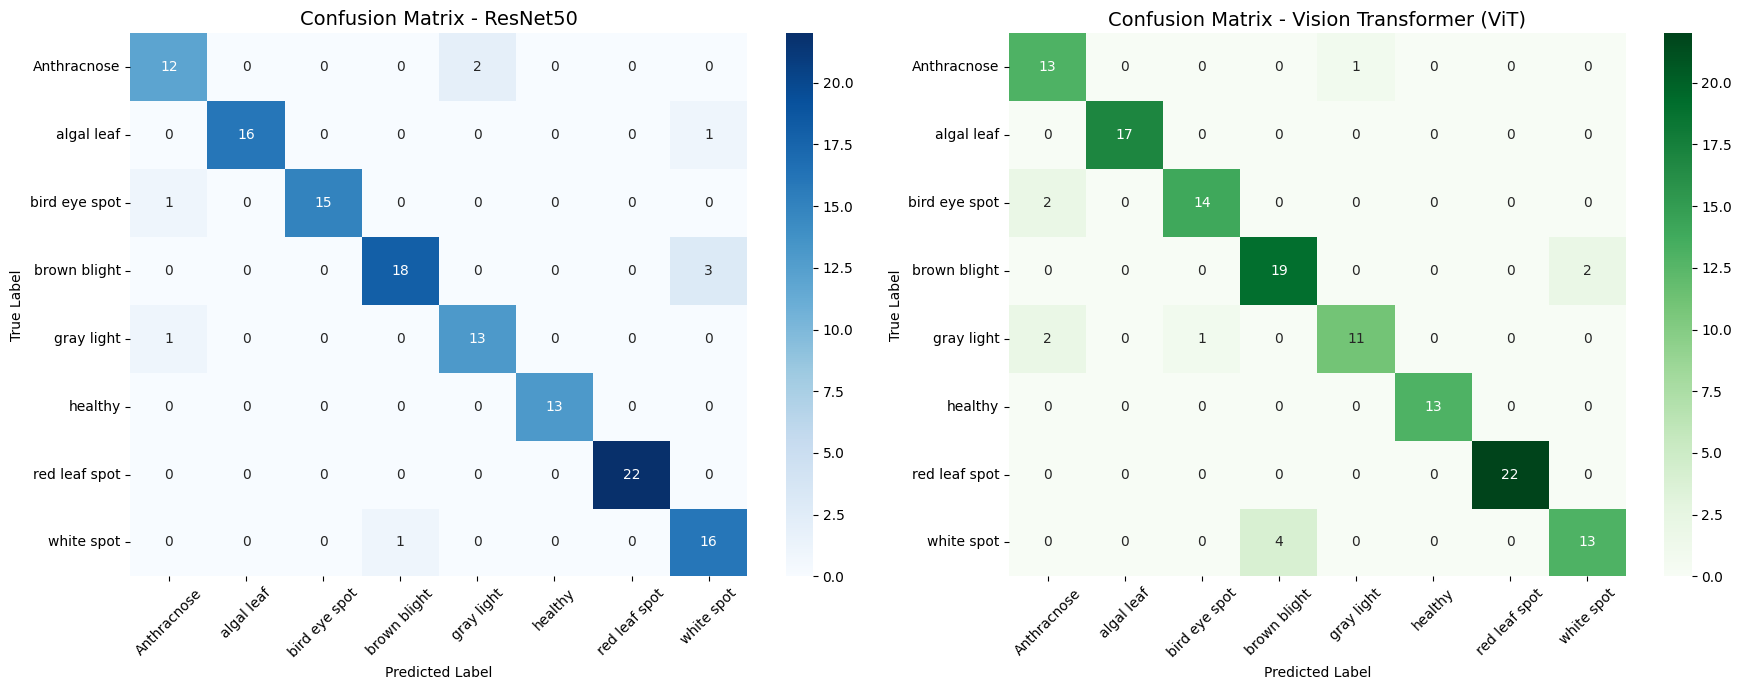

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

cm_res = confusion_matrix(labels_res, preds_res)
sns.heatmap(cm_res, annot=True, fmt='d', cmap='Blues', xticklabels=full_dataset.classes, yticklabels=full_dataset.classes, ax=axes[0])
axes[0].set_title("Confusion Matrix - ResNet50", fontsize=14)
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")
axes[0].tick_params(axis='x', rotation=45)

cm_vit = confusion_matrix(labels_vit, preds_vit)
sns.heatmap(cm_vit, annot=True, fmt='d', cmap='Greens', xticklabels=full_dataset.classes, yticklabels=full_dataset.classes, ax=axes[1])
axes[1].set_title("Confusion Matrix - Vision Transformer (ViT)", fontsize=14)
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


- Daun Sehat ("healthy") dan Daun Bercak Merah ("red leaf spot"):
  Kedua model mampu mengenali 100% tanpa ada satupun kesalahan prediksi. Ini menunjukkan visual daun sehat dan lesi merah memiliki fitur warna yang sangat kontras terhadap daun normal.
- Kebingungan Antara "white spot", "gray light", dan "Anthracnose":
  Sebagian kesalahan prediksi terjadi pada kelas-kelas bercak pucat/kering ini. Secara morfologi biologi tanaman teh, bercak putih (white spot) dan bercak kelabu (gray blight) memiliki kemiripan tekstur pada tepi daun yang mengering, sehingga model terkadang tertukar dalam membedakan batas kedua penyakit tersebut.

**TABEL KOMPARATIF AKHIR (UNTUK BAB 4 SKRIPSI) & KURVA LOSS/ACC**



=== TABEL PERBANDINGAN PERFORMA AKHIR (BAB 4 SKRIPSI) ===
                        Model  Accuracy (%)  Macro Precision  Macro Recall  Macro F1-Score  Weighted F1-Score
                     ResNet50         93.28           0.9339        0.9328           0.932             0.9338
Vision Transformer (ViT-B/16)         91.04           0.9134        0.9073           0.908             0.9104


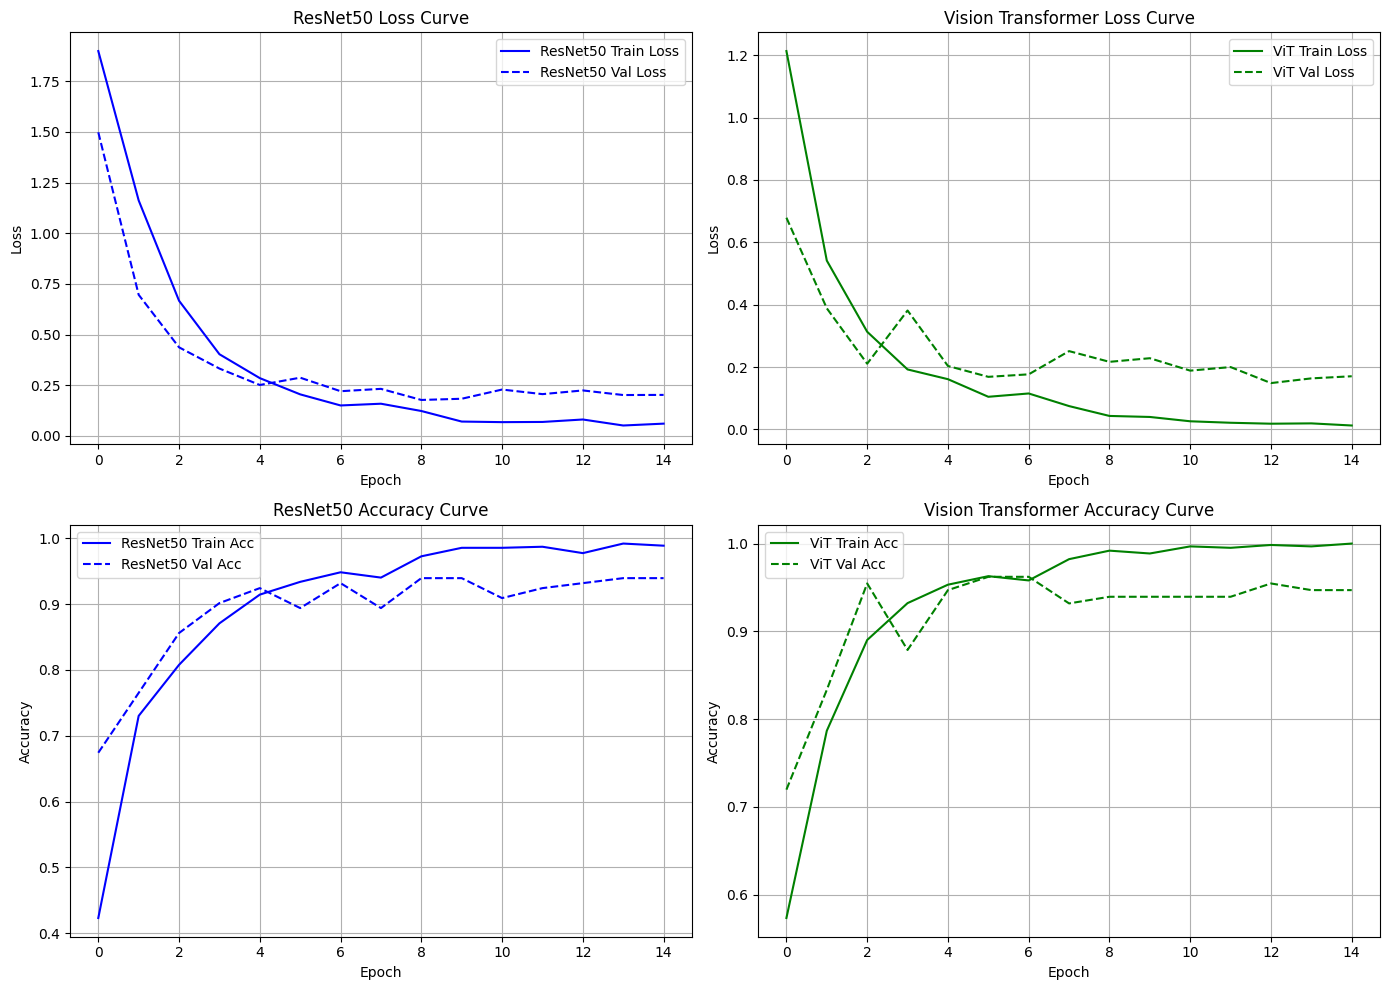

In [ ]:
# Tabel Perbandingan
df_compare = pd.DataFrame([metrics_res, metrics_vit])
print("\n=== TABEL PERBANDINGAN PERFORMA AKHIR (BAB 4 SKRIPSI) ===")
print(df_compare.to_string(index=False))

# Plot Kurva Training & Validation
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Loss ResNet vs ViT
axes[0, 0].plot(history_resnet['train_loss'], label='ResNet50 Train Loss', color='blue')
axes[0, 0].plot(history_resnet['val_loss'], label='ResNet50 Val Loss', color='blue', linestyle='--')
axes[0, 0].set_title("ResNet50 Loss Curve")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].legend()
axes[0, 0].grid(True)

axes[0, 1].plot(history_vit['train_loss'], label='ViT Train Loss', color='green')
axes[0, 1].plot(history_vit['val_loss'], label='ViT Val Loss', color='green', linestyle='--')
axes[0, 1].set_title("Vision Transformer Loss Curve")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Loss")
axes[0, 1].legend()
axes[0, 1].grid(True)

# Accuracy ResNet vs ViT
axes[1, 0].plot(history_resnet['train_acc'], label='ResNet50 Train Acc', color='blue')
axes[1, 0].plot(history_resnet['val_acc'], label='ResNet50 Val Acc', color='blue', linestyle='--')
axes[1, 0].set_title("ResNet50 Accuracy Curve")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Accuracy")
axes[1, 0].legend()
axes[1, 0].grid(True)

axes[1, 1].plot(history_vit['train_acc'], label='ViT Train Acc', color='green')
axes[1, 1].plot(history_vit['val_acc'], label='ViT Val Acc', color='green', linestyle='--')
axes[1, 1].set_title("Vision Transformer Accuracy Curve")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Accuracy")
axes[1, 1].legend()
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()


"Berdasarkan hasil pengujian komparatif antara arsitektur ResNet50 dan Vision Transformer (ViT-B/16) pada klasifikasi 8 kelas penyakit daun teh menggunakan 885 citra digital, diperoleh kesimpulan bahwa model ResNet50 menunjukkan performa generalisasi yang lebih unggul dengan nilai Accuracy sebesar 93.28%, Macro Precision 0.9339, Macro Recall 0.9328, dan Macro F1-Score 0.9320 pada dataset pengujian (test set). Sementara itu, Vision Transformer memperoleh Accuracy 91.04% dan Macro F1-Score 0.9080. Keunggulan ResNet50 dipengaruhi oleh adanya inductive bias spasial pada arsitektur CNN yang lebih optimal dalam memproses dataset citra berskala sedang dibandingkan arsitektur Transformer yang memerlukan volume data lebih masif."